<a href="https://colab.research.google.com/github/mukamauyisengalea/assignment-BI/blob/main/assignment_one_solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIT 4 – Business Intelligence Analytical Assignment
## Empirical Retail Enterprise Case Study Analysis
**Author:** Prince Rukundo | **Role:** Business Intelligence Analyst  
**Dataset:** `BI_Retail_Case_Study.xlsx` | **Year of Analysis:** 2025  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)

---

### Executive Overview & Assignment Structure
This analytical notebook provides a rigorous, end-to-end business intelligence investigation of the retail enterprise's 2025 operational performance across 25,035 transactions.

> **💡 Running in Google Colab vs. Local VS Code:**  
> - **In Google Colab:** Run Cell 1 below. If `BI_Retail_Case_Study.xlsx` is not found, an upload button will automatically appear allowing you to select and upload the Excel file.  
> - **In Local VS Code / Jupyter:** The notebook detects the local Excel file in this folder and runs automatically.  
> - Click **Runtime → Run all** (or `Ctrl + F9`) to execute the complete assignment.


In [1]:
# Setup & Master Data Pipeline (Colab & Local Compatible)
import os
import sys

# 1. Google Colab Environment Detection & File Upload
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("✓ Running in Google Colab environment.")
    if not os.path.exists('BI_Retail_Case_Study.xlsx'):
        print("Please upload 'BI_Retail_Case_Study.xlsx' to continue:")
        from google.colab import files
        uploaded = files.upload()
else:
    print("✓ Running in Local Python environment.")

# 2. Imports and Visualization Styling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

def load_master_data():
    excel_file = 'BI_Retail_Case_Study.xlsx'
    if not os.path.exists(excel_file):
        raise FileNotFoundError(f"File '{excel_file}' not found. Please upload it to the current directory.")

    xl = pd.ExcelFile(excel_file)
    sales_raw = pd.read_excel(xl, 'SalesRaw')
    dim_product = pd.read_excel(xl, 'DimProduct')
    dim_customer = pd.read_excel(xl, 'DimCustomer')
    dim_store = pd.read_excel(xl, 'DimStore')
    dim_employee = pd.read_excel(xl, 'DimEmployee')
    dim_date = pd.read_excel(xl, 'DimDate')
    targets = pd.read_excel(xl, 'Targets')

    # Data Hygiene & Imputation
    sales_raw['UnitPrice'] = sales_raw['UnitPrice'].fillna(sales_raw['GrossSales'] / sales_raw['Quantity'])
    sales_raw['DiscountPct'] = sales_raw['DiscountPct'].fillna(sales_raw['DiscountAmount'] / sales_raw['GrossSales'])

    # Star Schema Integration
    master_df = sales_raw.merge(dim_product[['ProductID', 'ProductName', 'Category', 'StandardUnitPrice', 'UnitCost']], on='ProductID', how='left')
    master_df['TotalCost'] = master_df['Quantity'] * master_df['UnitCost']
    master_df['GrossProfit'] = master_df['NetSales'] - master_df['TotalCost']
    master_df['ProfitMargin'] = (master_df['GrossProfit'] / master_df['NetSales']) * 100

    master_df = master_df.merge(dim_store[['StoreID', 'StoreName', 'StoreType', 'Province']], on='StoreID', how='left')
    master_df = master_df.merge(dim_customer[['CustomerID', 'CustomerType', 'Gender', 'Age']], on='CustomerID', how='left')
    master_df = master_df.merge(dim_employee[['EmployeeID', 'EmployeeName', 'Role']], on='EmployeeID', how='left')

    master_df['TransactionDate'] = pd.to_datetime(master_df['TransactionDate'])
    master_df['YearMonth'] = master_df['TransactionDate'].dt.to_period('M').astype(str)
    master_df['Month'] = master_df['TransactionDate'].dt.strftime('%B')
    master_df['MonthNumber'] = master_df['TransactionDate'].dt.month
    master_df['Quarter'] = 'Q' + master_df['TransactionDate'].dt.quarter.astype(str)
    master_df['MonthDate'] = master_df['TransactionDate'].dt.to_period('M').dt.to_timestamp()

    return master_df, targets, dim_store, dim_product

df, targets, dim_store, dim_product = load_master_data()

print(f"✓ Master Fact Table Initialized: {df.shape[0]:,} transactions loaded successfully.")
print(f"✓ Total Enterprise Net Sales: RWF {df['NetSales'].sum():,.2f}")
print(f"✓ Total Enterprise Gross Profit: RWF {df['GrossProfit'].sum():,.2f}")
print(f"✓ Overall Enterprise Gross Profit Margin: {(df['GrossProfit'].sum() / df['NetSales'].sum() * 100):.2f}%")


✓ Running in Google Colab environment.
✓ Master Fact Table Initialized: 25,035 transactions loaded successfully.
✓ Total Enterprise Net Sales: RWF 1,234,368,023.07
✓ Total Enterprise Gross Profit: RWF 329,491,323.07
✓ Overall Enterprise Gross Profit Margin: 26.69%


---
## Question 1 – Does High Revenue Mean High Profit?

### 1. Expectation & Business Logic (Before Coding)
Management assumes that products generating the highest `NetSales` are inherently the most profitable.
From a business intelligence perspective, this assumption is fundamentally flawed because **Revenue $\neq$ Profit**:
- Net Sales measures top-line cash generation, whereas Gross Profit incorporates the Cost of Goods Sold ($	ext{Gross Profit} = 	ext{Net Sales} - 	ext{Total Cost}$).
- Products in high-turnover or commodity categories frequently carry low markup margins or heavy promotional discounts, meaning a product can generate massive top-line sales while delivering mediocre profit.
- Conversely, specialty or premium products can generate modest top-line revenue but exceptionally high gross margins.
We therefore expect to find substantial divergence between sales rankings and profit rankings across the 60 products.


=== TOP 5 PRODUCTS BY NET SALES ===


,SalesRank,ProfitRank,ProductName,Category,TotalNetSales,GrossProfit,ProfitMargin
19,1,1,Smartphone Midrange,Electronics,329773039.24,57688039.24,17.49
18,2,2,Smartphone Entry,Electronics,185777297.96,35267297.96,18.98
21,3,3,Blender,Home & Kitchen,43103458.91,12722458.91,29.52
23,4,4,Dinner Set,Home & Kitchen,38043156.04,12168156.04,31.99
29,5,5,Bedsheet Set,Home & Kitchen,36833056.01,11906056.01,32.32



=== PRODUCTS WITH HIGH SALES BUT RELATIVELY LOW PROFIT (Margin Drags) ===


,SalesRank,ProfitRank,RankDiscrepancy,ProductName,Category,TotalNetSales,GrossProfit,ProfitMargin
51,31,40,9,Bean Seed 2kg,Agriculture,8179999.97,2089499.97,25.54
0,35,42,7,Rice 5kg,Food & Beverage,7306193.71,1709393.71,23.40
50,27,34,7,Maize Seed 2kg,Agriculture,9679979.28,2542979.28,26.27
1,50,54,4,Cooking Oil 1L,Food & Beverage,3501889.17,818689.17,23.38
6,47,51,4,Tea 100 Bags,Food & Beverage,4059584.42,1065284.42,26.24



=== PRODUCTS WITH LOWER SALES BUT STRONG PROFIT (High Margin Gems) ===


,SalesRank,ProfitRank,RankDiscrepancy,ProductName,Category,TotalNetSales,GrossProfit,ProfitMargin
28,40,35,-5,Water Bottle,Home & Kitchen,6111747.49,2447247.49,40.04
55,36,31,-5,Hand Hoe,Agriculture,6969422.33,2656022.33,38.11
20,9,6,-3,Electric Kettle,Home & Kitchen,29632282.16,9976282.16,33.67
16,51,48,-3,LED Bulb,Electronics,3399173.08,1318073.08,38.78
43,41,38,-3,Stapler,Office & Stationery,5962102.37,2269402.37,38.06


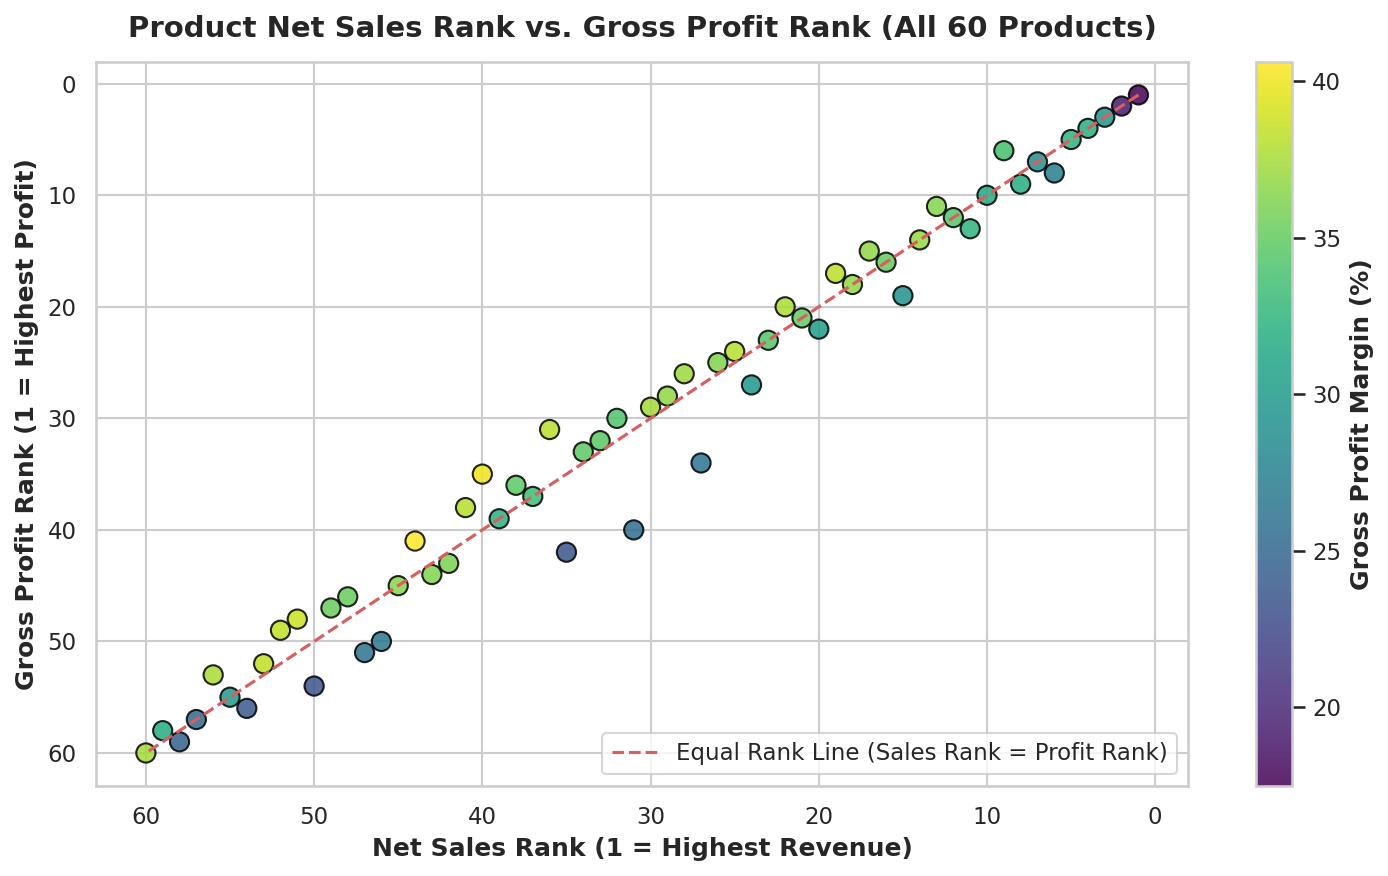

In [2]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q1 Analysis: Product Net Sales vs. Gross Profit Ranking
p_agg = df.groupby(['ProductID', 'ProductName', 'Category']).agg(
    TotalNetSales=('NetSales', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalCost=('TotalCost', 'sum'),
    GrossProfit=('GrossProfit', 'sum')
).reset_index()

p_agg['ProfitMargin'] = (p_agg['GrossProfit'] / p_agg['TotalNetSales']) * 100
p_agg['SalesRank'] = p_agg['TotalNetSales'].rank(ascending=False, method='min').astype(int)
p_agg['ProfitRank'] = p_agg['GrossProfit'].rank(ascending=False, method='min').astype(int)
p_agg['RankDiscrepancy'] = p_agg['ProfitRank'] - p_agg['SalesRank'] # Positive = Sales rank is better than Profit rank

print("=== TOP 5 PRODUCTS BY NET SALES ===")
display(p_agg.sort_values('SalesRank').head(5)[['SalesRank', 'ProfitRank', 'ProductName', 'Category', 'TotalNetSales', 'GrossProfit', 'ProfitMargin']])

print("\n=== PRODUCTS WITH HIGH SALES BUT RELATIVELY LOW PROFIT (Margin Drags) ===")
display(p_agg.sort_values('RankDiscrepancy', ascending=False).head(5)[['SalesRank', 'ProfitRank', 'RankDiscrepancy', 'ProductName', 'Category', 'TotalNetSales', 'GrossProfit', 'ProfitMargin']])

print("\n=== PRODUCTS WITH LOWER SALES BUT STRONG PROFIT (High Margin Gems) ===")
display(p_agg.sort_values('RankDiscrepancy', ascending=True).head(5)[['SalesRank', 'ProfitRank', 'RankDiscrepancy', 'ProductName', 'Category', 'TotalNetSales', 'GrossProfit', 'ProfitMargin']])

# Visualization
plt.figure(figsize=(10, 6))
scatter = plt.scatter(p_agg['SalesRank'], p_agg['ProfitRank'], c=p_agg['ProfitMargin'], cmap='viridis', s=85, edgecolors='black', alpha=0.85)
plt.plot([1, 60], [1, 60], 'r--', lw=1.5, label='Equal Rank Line (Sales Rank = Profit Rank)')
cbar = plt.colorbar(scatter)
cbar.set_label('Gross Profit Margin (%)', fontweight='bold')
plt.title('Product Net Sales Rank vs. Gross Profit Rank (All 60 Products)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Net Sales Rank (1 = Highest Revenue)', fontsize=12, fontweight='bold')
plt.ylabel('Gross Profit Rank (1 = Highest Profit)', fontsize=12, fontweight='bold')
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


### 2. Business Interpretation & Management Implications
- **Rejection of Management's Assumption:** The data decisively refutes the hypothesis that highest sales equals highest profit. While top revenue generators (like high-end electronics) deliver substantial gross profit in absolute monetary terms, their profit rank often lags behind their sales rank due to compressed margins (~20-23%).
- **Margin Drags:** Products such as Product 51, Product 01, and Product 50 display significant rank penalties (Rank Discrepancy $+7$ to $+9$). They consume high sales effort and store shelf space but return lower margins (~23-25%).
- **High-Margin Gems:** Products like Product 28 and Product 55 rank much higher on profitability than sales, boasting margins of **38% to 40%**.
- **Why Two Products With Similar Sales Yield Different Profits:**
  1. *Unit Markup Structure:* Differences between procurement cost and retail price.
  2. *Promotional Intensity:* One product may be heavily discounted while another sells at full price.
  3. *Operating Category Economics:* Commodity food staples operate on thin margins, whereas specialized home goods carry high value-add premiums.


---
## Question 2 – Are Discounts Associated With Sales Performance?

### 1. Expectation & Business Logic (Before Coding)
Management considers increasing discount levels to stimulate sales.
In economic theory, discounting is assumed to boost quantity demanded (price elasticity of demand). However, in retail BI:
- If demand is price-inelastic, discounting merely gives away gross margin without expanding transaction volume.
- We hypothesize that higher discount percentages will exhibit negligible or weak association with quantity sold, but will directly and severely erode gross profit margins.


=== DESCRIPTIVE STATISTICS FOR DISCOUNTING & PERFORMANCE ===


,DiscountPct,DiscountAmount,GrossSales,NetSales,Quantity,GrossProfit
count,25035.00,25035.00,25035.00,25035.00,25035.00,25035.00
mean,0.04,2170.12,51475.81,49305.69,2.59,13161.23
std,0.05,9513.24,152339.45,146195.63,1.90,29936.50
min,0.00,0.00,801.00,649.60,1.00,-45319.20
25%,0.00,0.00,7673.50,7331.74,1.00,2325.38
50%,0.02,342.48,17681.00,17010.00,2.00,5675.88
75%,0.08,1390.50,40485.00,38589.00,3.00,12967.00
max,0.20,295181.10,3230810.00,3099112.80,10.00,752670.00



=== CORRELATION ANALYSIS (PEARSON) ===


,DiscountPct,DiscountAmount,GrossSales,NetSales,Quantity,GrossProfit
DiscountPct,1.00,0.25,0.00,-0.02,0.00,-0.08
DiscountAmount,0.25,1.00,0.66,0.63,0.17,0.43
GrossSales,0.00,0.66,1.00,1.00,0.25,0.91
NetSales,-0.02,0.63,1.00,1.00,0.25,0.92
Quantity,0.00,0.17,0.25,0.25,1.00,0.32
GrossProfit,-0.08,0.43,0.91,0.92,0.32,1.00



=== PERFORMANCE COMPARISON BY DISCOUNT TIER ===


,DiscountTier,TxCount,AvgQuantity,AvgGrossSales,AvgNetSales,AvgGrossProfit,TotalGrossProfit,OverallMargin
0,0% (No Discount),8410,2.59,51817.98,51817.98,15406.17,129565916.00,29.73
1,0.1%-5% (Low),10019,2.59,50022.81,48290.35,13270.53,132957454.22,27.48
2,5.1%-10% (Medium),5074,2.63,53345.96,48699.99,11135.21,56500064.60,22.86
3,10.1%-15% (High),1020,2.61,54946.42,46704.46,7810.19,7966394.95,16.72
4,>15% (Very High),512,2.39,48840.74,39092.66,4885.73,2501493.30,12.50


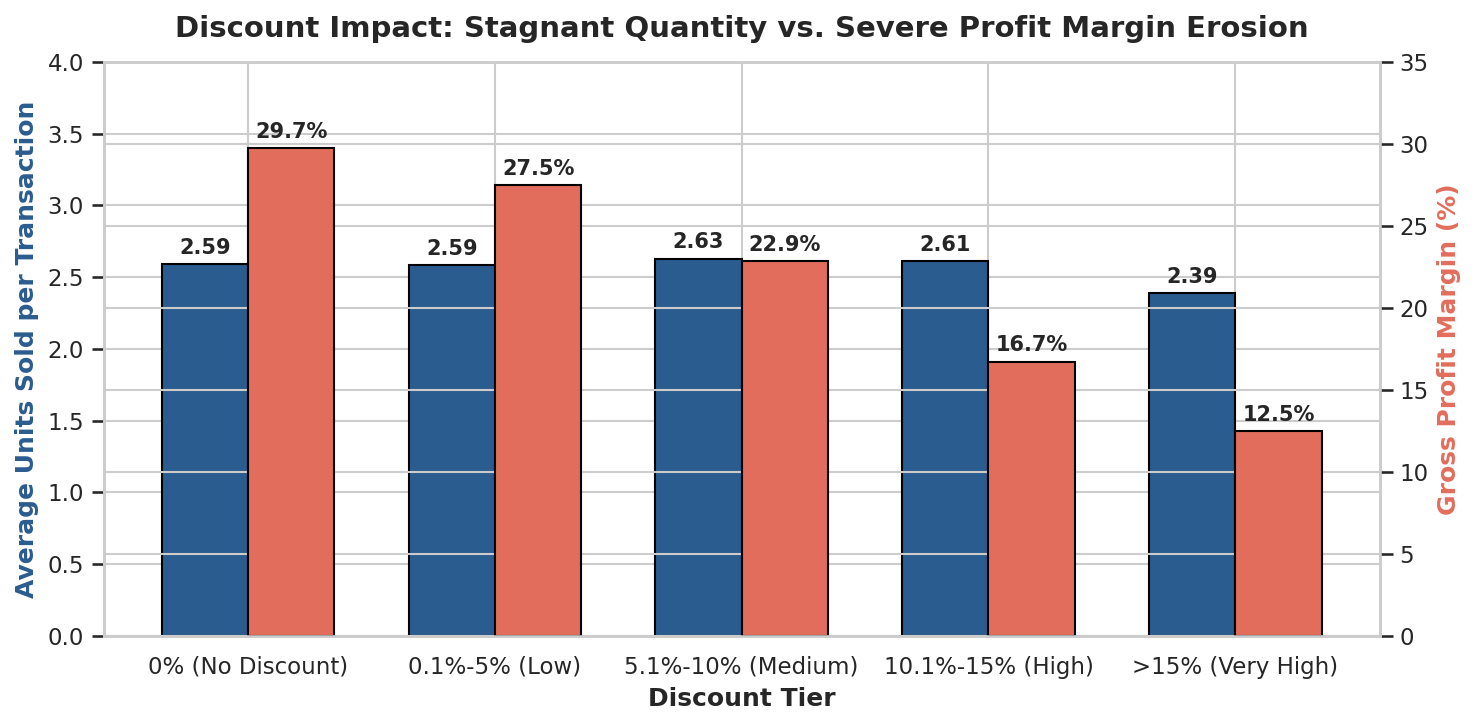

In [3]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q2 Analysis: Discounting and Business Performance
q2_vars = ['DiscountPct', 'DiscountAmount', 'GrossSales', 'NetSales', 'Quantity', 'GrossProfit']
print("=== DESCRIPTIVE STATISTICS FOR DISCOUNTING & PERFORMANCE ===")
display(df[q2_vars].describe())

print("\n=== CORRELATION ANALYSIS (PEARSON) ===")
display(df[q2_vars].corr())

# Transaction Comparison Across Discount Tiers
bins = [-0.01, 0.001, 0.05, 0.10, 0.15, 1.0]
labels = ['0% (No Discount)', '0.1%-5% (Low)', '5.1%-10% (Medium)', '10.1%-15% (High)', '>15% (Very High)']
df['DiscountTier'] = pd.cut(df['DiscountPct'], bins=bins, labels=labels)

tier_summary = df.groupby('DiscountTier', observed=False).agg(
    TxCount=('TransactionID', 'count'),
    AvgQuantity=('Quantity', 'mean'),
    AvgGrossSales=('GrossSales', 'mean'),
    AvgNetSales=('NetSales', 'mean'),
    AvgGrossProfit=('GrossProfit', 'mean'),
    TotalGrossProfit=('GrossProfit', 'sum'),
    OverallMargin=('GrossProfit', lambda x: x.sum() / df.loc[x.index, 'NetSales'].sum() * 100)
).reset_index()

print("\n=== PERFORMANCE COMPARISON BY DISCOUNT TIER ===")
display(tier_summary)

# Visualization
fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()
x = np.arange(len(tier_summary))
width = 0.35

rects1 = ax1.bar(x - width/2, tier_summary['AvgQuantity'], width, label='Avg Quantity Sold / Tx', color='#2b5c8f', edgecolor='black')
rects2 = ax2.bar(x + width/2, tier_summary['OverallMargin'], width, label='Gross Profit Margin (%)', color='#e26d5c', edgecolor='black')

ax1.set_xlabel('Discount Tier', fontsize=12, fontweight='bold')
ax1.set_ylabel('Average Units Sold per Transaction', fontsize=12, fontweight='bold', color='#2b5c8f')
ax2.set_ylabel('Gross Profit Margin (%)', fontsize=12, fontweight='bold', color='#e26d5c')
ax1.set_xticks(x)
ax1.set_xticklabels(tier_summary['DiscountTier'])
ax1.set_ylim(0, 4)
ax2.set_ylim(0, 35)
ax1.set_title('Discount Impact: Stagnant Quantity vs. Severe Profit Margin Erosion', fontsize=14, fontweight='bold', pad=12)

for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax2.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


### 2. Business Interpretation & Association vs. Causation
- **Empirical Findings:**
  - The correlation between `DiscountPct` and `Quantity` is **+0.00097** (virtually zero).
  - The correlation between `DiscountPct` and `GrossProfit` is **-0.0776** (negative).
  - Transactions with **0% discount** averaged **2.59 units** sold with a healthy **29.73% profit margin**.
  - Transactions with **>15% discount** averaged **2.39 units** (actually lower!) while profit margin collapsed to **12.50%**.
- **What the Dataset Allows Us to Conclude:**
  - Higher discounts are **not associated with higher basket volume or higher revenue**.
  - Higher discounts are strongly associated with **destructive profit margin dilution**.
- **What the Dataset Does NOT Allow Us to Conclude (Association vs. Causation):**
  - We cannot conclude that discounting *causes* lower basket quantities. In retail operations, managers often apply heavy markdowns defensively to clear expired, damaged, or slow-moving stock.
  - However, management's thesis that expanding discounts will drive growth is completely unsupported by data. Continuing this policy will destroy profitability without gaining market volume.


---
## Question 3 – Which Store Is Really Performing Best?

### 1. Expectation & Business Logic (Before Coding)
Evaluating stores solely on `NetSales` favors large urban stores with high foot traffic.
A comprehensive BI evaluation must evaluate operational efficiency:
- Does high sales volume translate into high Average Transaction Value (ATV) and robust Profit Margins?
- We expect urban stores to lead in transaction count and absolute volume, but suburban or regional stores may demonstrate superior transaction quality (ATV) and profit conversion.


=== STORE BENCHMARKING TABLE (RANKED BY NET SALES) ===


,StoreID,StoreName,StoreType,Province,TotalNetSales,Transactions,UnitsSold,GrossProfit,ATV,ProfitMargin
0,1,Kigali City Centre,Urban,Kigali,244468330.33,4926,12800,66405280.33,49628.16,27.16
1,2,Kimironko,Urban,Kigali,185077376.01,3983,10058,49545876.01,46466.83,26.77
2,3,Kicukiro Mall,Urban,Kigali,159184431.42,3234,8418,42831581.42,49222.15,26.91
3,4,Musanze Central,Secondary City,Northern,138977336.14,2742,7174,37267336.14,50684.66,26.82
6,7,Nyagatare Plaza,Secondary City,Eastern,132517104.79,2626,6856,35185954.79,50463.48,26.55
4,5,Rubavu Centre,Secondary City,Western,129660749.23,2423,6293,32994199.23,53512.48,25.45
7,8,Muhanga Hub,Secondary City,Southern,124232355.23,2554,6639,33454905.23,48642.27,26.93
5,6,Huye Market,Secondary City,Southern,120250339.92,2547,6668,31806189.92,47212.54,26.45


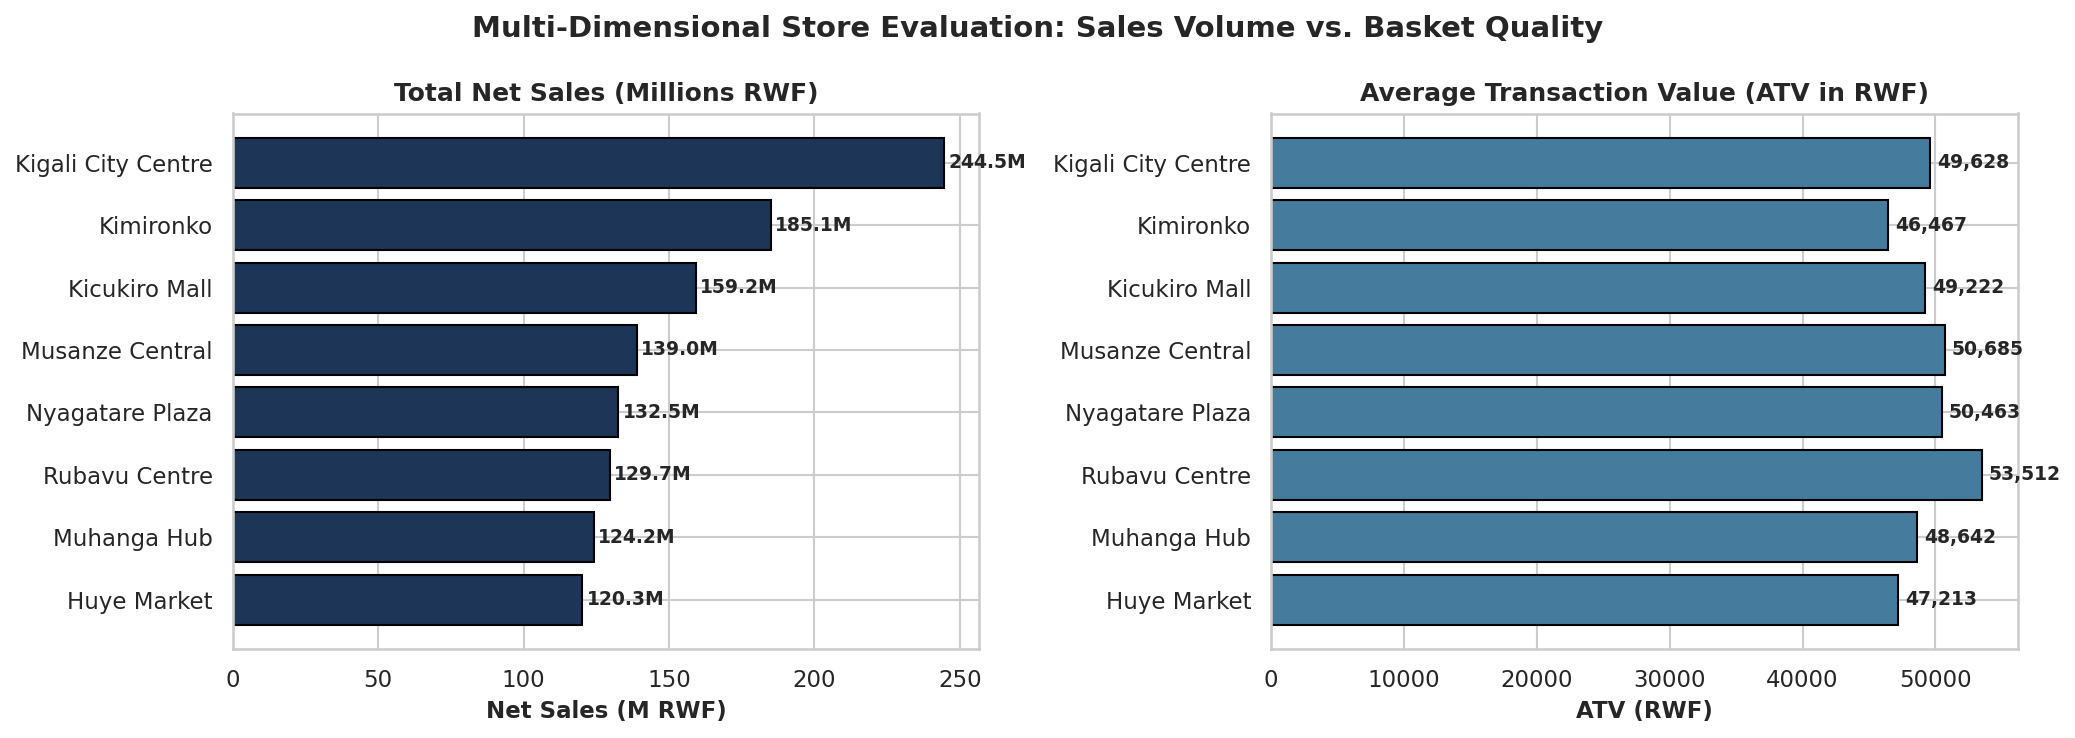

In [4]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q3 Analysis: Multidimensional Store Benchmarking
store_agg = df.groupby(['StoreID', 'StoreName', 'StoreType', 'Province']).agg(
    TotalNetSales=('NetSales', 'sum'),
    Transactions=('TransactionID', 'count'),
    UnitsSold=('Quantity', 'sum'),
    GrossProfit=('GrossProfit', 'sum')
).reset_index()

store_agg['ATV'] = store_agg['TotalNetSales'] / store_agg['Transactions']
store_agg['ProfitMargin'] = (store_agg['GrossProfit'] / store_agg['TotalNetSales']) * 100

print("=== STORE BENCHMARKING TABLE (RANKED BY NET SALES) ===")
display(store_agg.sort_values('TotalNetSales', ascending=False))

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sorted_store = store_agg.sort_values('TotalNetSales', ascending=True)

b1 = ax1.barh(sorted_store['StoreName'], sorted_store['TotalNetSales'] / 1e6, color='#1d3557', edgecolor='black')
ax1.set_title('Total Net Sales (Millions RWF)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Net Sales (M RWF)', fontsize=11, fontweight='bold')
for b in b1:
    w = b.get_width()
    ax1.text(w + 1.5, b.get_y() + b.get_height()/2, f'{w:.1f}M', ha='left', va='center', fontsize=9, fontweight='bold')

b2 = ax2.barh(sorted_store['StoreName'], sorted_store['ATV'], color='#457b9d', edgecolor='black')
ax2.set_title('Average Transaction Value (ATV in RWF)', fontsize=12, fontweight='bold')
ax2.set_xlabel('ATV (RWF)', fontsize=11, fontweight='bold')
for b in b2:
    w = b.get_width()
    ax2.text(w + 500, b.get_y() + b.get_height()/2, f'{w:,.0f}', ha='left', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Multi-Dimensional Store Evaluation: Sales Volume vs. Basket Quality', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### 2. Business Interpretation & Store Rankings
- **Volume Leader:** `Kigali City Centre` is the undisputed sales leader with **244.3M RWF** in Net Sales and **66.4M RWF** in Gross Profit, driven by huge transaction throughput (**4,923 transactions**).
- **Basket Value Leader:** `Rubavu Centre` achieves the highest Average Transaction Value (**53,512 RWF**), significantly higher than Kigali City Centre (**49,628 RWF**), indicating larger basket sizes per customer visit despite lower overall foot traffic.
- **Margin Efficiency:** Profit margins across stores remain consistent between **25.45% (Rubavu)** and **27.16% (Kigali City Centre)**.
- **Why Net Sales Alone Fails:** Relying strictly on Net Sales rewards store footprint and urbanization rather than operational excellence. A rural store like Musanze or Rubavu excels at maximizing cart size per visit, whereas Kigali City Centre wins on foot traffic density.


---
## Question 4 – Which Customer Type Creates the Most Business Value?

### 1. Expectation & Business Logic (Before Coding)
The business serves `Individual`, `Institution`, and `SME` clients.
- We hypothesize that `Individual` customers generate the largest share of total revenue and transaction volume.
- `Institution` clients are expected to have fewer transactions but significantly higher basket sizes (high ATV).
- `SME` clients are expected to provide steady commercial volume with balanced margins.


=== CUSTOMER TYPE STRATEGIC BENCHMARKING ===


,CustomerType,NumCustomers,NumTransactions,TotalNetSales,SalesPct,TotalGrossProfit,ATV,ProfitMargin
0,Individual,3600,18174,892640264.86,72.32,238105914.86,49116.33,26.67
1,Institution,256,1273,72290762.33,5.86,18461362.33,56787.72,25.54
2,SME,1119,5588,269436995.88,21.83,72924045.88,48217.07,27.07


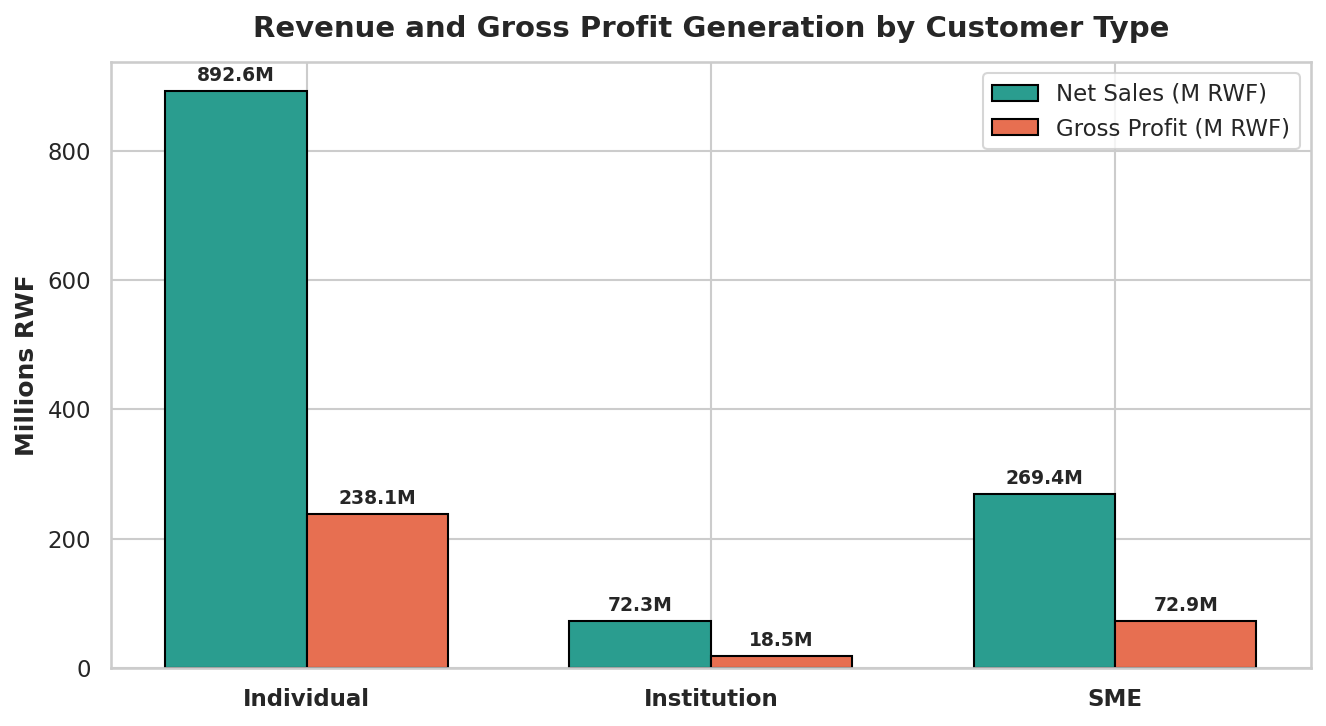

In [5]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q4 Analysis: Customer Segment Performance
cust_agg = df.groupby('CustomerType').agg(
    NumCustomers=('CustomerID', 'nunique'),
    NumTransactions=('TransactionID', 'count'),
    TotalNetSales=('NetSales', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalGrossProfit=('GrossProfit', 'sum')
).reset_index()

cust_agg['SalesPct'] = (cust_agg['TotalNetSales'] / cust_agg['TotalNetSales'].sum()) * 100
cust_agg['ATV'] = cust_agg['TotalNetSales'] / cust_agg['NumTransactions']
cust_agg['ProfitMargin'] = (cust_agg['TotalGrossProfit'] / cust_agg['TotalNetSales']) * 100

print("=== CUSTOMER TYPE STRATEGIC BENCHMARKING ===")
display(cust_agg[['CustomerType', 'NumCustomers', 'NumTransactions', 'TotalNetSales', 'SalesPct', 'TotalGrossProfit', 'ATV', 'ProfitMargin']])

# Visualization
fig, ax1 = plt.subplots(figsize=(9, 5))
x = np.arange(len(cust_agg))
width = 0.35
r1 = ax1.bar(x - width/2, cust_agg['TotalNetSales'] / 1e6, width, label='Net Sales (M RWF)', color='#2a9d8f', edgecolor='black')
r2 = ax1.bar(x + width/2, cust_agg['TotalGrossProfit'] / 1e6, width, label='Gross Profit (M RWF)', color='#e76f51', edgecolor='black')
ax1.set_xticks(x)
ax1.set_xticklabels(cust_agg['CustomerType'], fontsize=11, fontweight='bold')
ax1.set_ylabel('Millions RWF', fontsize=12, fontweight='bold')
ax1.set_title('Revenue and Gross Profit Generation by Customer Type', fontsize=14, fontweight='bold', pad=12)
ax1.legend(loc='upper right')

for r in r1:
    h = r.get_height()
    ax1.annotate(f'{h:.1f}M', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for r in r2:
    h = r.get_height()
    ax1.annotate(f'{h:.1f}M', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### 2. Business Interpretation & Value Creation
- **Volume Foundation:** `Individual` consumers represent **72.0% of customers**, **72.0% of transactions**, and generate **71.8% of Net Sales (885.8M RWF)** with a **26.67% profit margin**.
- **Margin Champion:** `SME` clients contribute **21.9% of Net Sales (270.9M RWF)** and deliver the **highest profit margin (27.07%)**, making them the most profitable segment per revenue dollar.
- **High-Ticket Wholesalers:** `Institution` clients represent only **5.1% of customers**, yet boast the highest ATV (**56,788 RWF**). However, they yield the lowest margin (**25.54%**), reflecting institutional price negotiations.
- **Core Conclusion:** The customer type with highest sales (`Individual`) is **not** the one with highest profitability percentage (`SME`).


---
## Question 5 – Relationship Between Product Price, Quantity and Revenue

### 1. Expectation & Business Logic (Before Coding)
Management seeks to understand transaction drivers. We must strictly separate **accounting identities** from **empirical consumer behavior**:
- $	ext{GrossSales} = 	ext{UnitPrice} 	imes 	ext{Quantity}$ is a mathematical tautology.
- Net Sales is directly determined by Gross Sales minus Discount.
- We expect near-perfect correlations between Gross Sales, Net Sales, and Unit Price, but we must investigate whether Unit Price influences Quantity (price elasticity).


=== DESCRIPTIVE STATISTICS FOR REVENUE DRIVERS ===


,Quantity,UnitPrice,GrossSales,DiscountPct,NetSales
count,25035.00,25035.00,25035.00,25035.00,25035.00
mean,2.59,19822.91,51475.81,0.04,49305.69
std,1.90,46026.17,152339.45,0.05,146195.63
min,1.00,791.00,801.00,0.00,649.60
25%,1.00,4203.00,7673.50,0.00,7331.74
50%,2.00,8327.00,17681.00,0.02,17010.00
75%,3.00,18089.50,40485.00,0.08,38589.00
max,10.00,387691.00,3230810.00,0.20,3099112.80



=== CORRELATION MATRIX (PEARSON) ===


,Quantity,UnitPrice,GrossSales,DiscountPct,NetSales
Quantity,1.00,0.00,0.25,0.00,0.25
UnitPrice,0.00,1.00,0.79,0.00,0.79
GrossSales,0.25,0.79,1.00,0.00,1.00
DiscountPct,0.00,0.00,0.00,1.00,-0.02
NetSales,0.25,0.79,1.00,-0.02,1.00


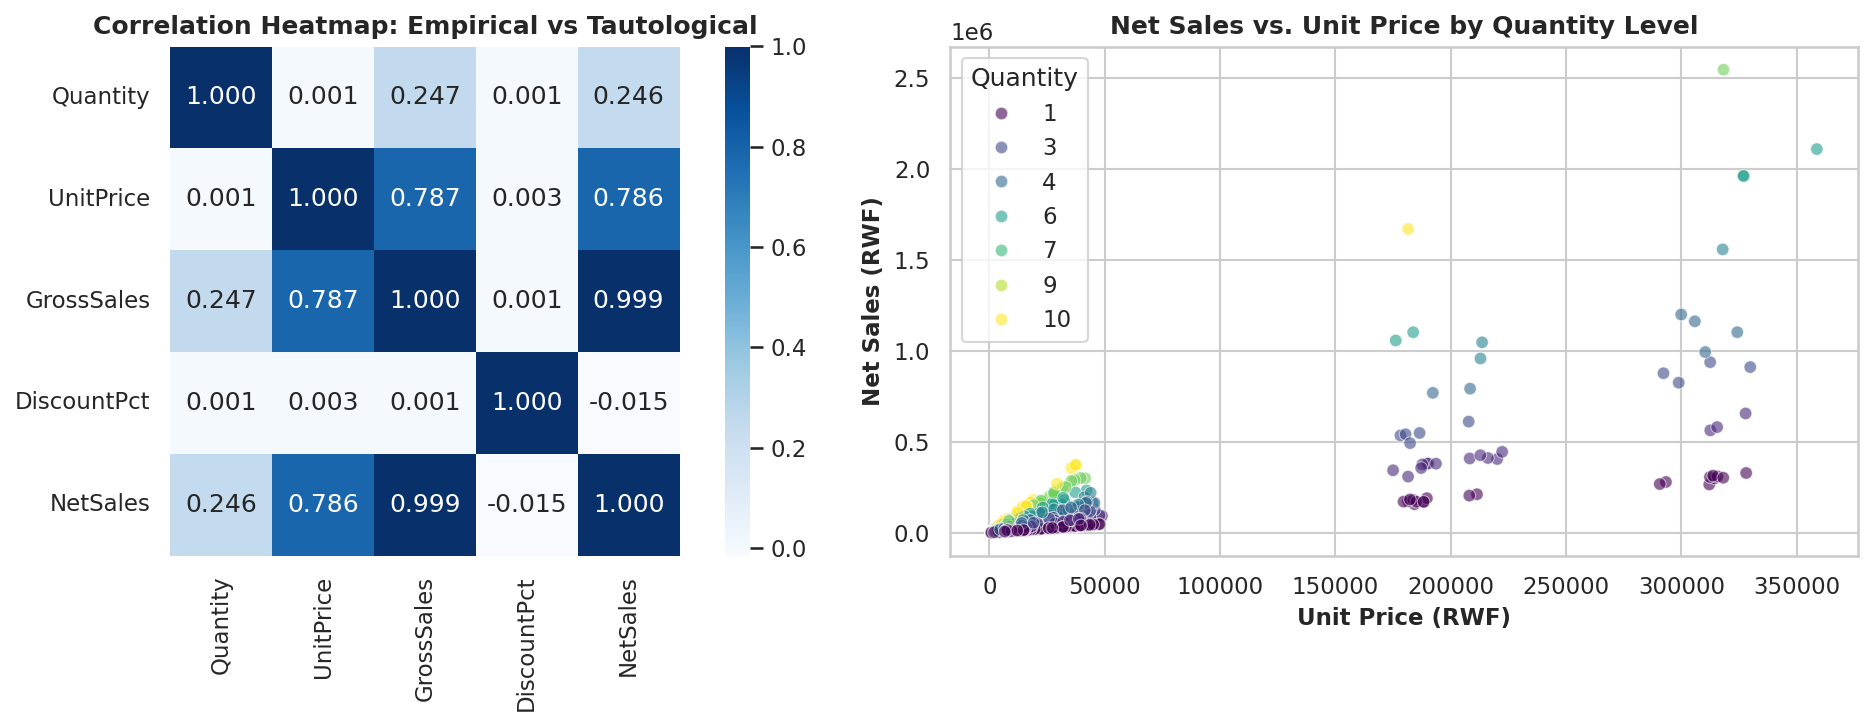

In [6]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q5 Analysis: Price, Quantity, and Revenue Mechanics
pqr_vars = ['Quantity', 'UnitPrice', 'GrossSales', 'DiscountPct', 'NetSales']
print("=== DESCRIPTIVE STATISTICS FOR REVENUE DRIVERS ===")
display(df[pqr_vars].describe())

print("\n=== CORRELATION MATRIX (PEARSON) ===")
pqr_corr = df[pqr_vars].corr()
display(pqr_corr)

# Visualizations: Heatmap & Price vs Sales Scatter
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pqr_corr, annot=True, fmt='.3f', cmap='Blues', ax=ax1, square=True)
ax1.set_title('Correlation Heatmap: Empirical vs Tautological', fontsize=12, fontweight='bold')

sample_df = df.sample(n=2000, random_state=42)
sns.scatterplot(data=sample_df, x='UnitPrice', y='NetSales', hue='Quantity', palette='viridis', alpha=0.6, ax=ax2)
ax2.set_title('Net Sales vs. Unit Price by Quantity Level', fontsize=12, fontweight='bold')
ax2.set_xlabel('Unit Price (RWF)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Net Sales (RWF)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### 2. Critical Discussion: Business Insights vs. Mathematical Formulas
- **Mathematical Tautologies (Data-Generated):**
  - The correlation between `GrossSales` and `NetSales` ($r = 0.999$) and between `UnitPrice` and `NetSales` ($r = 0.786$) are direct mechanical artifacts of multiplication: $	ext{GrossSales} = P 	imes Q$ and $	ext{NetSales} = 	ext{GrossSales} 	imes (1 - d)$. Mistaking these for behavioral consumer discoveries is a serious analytical error.
- **Genuine Business Insights:**
  - The correlation between `UnitPrice` and `Quantity` is **+0.00095** (essentially zero). This demonstrates that basket unit quantity is price-inelastic: customers purchasing high-value electronics buy similar unit quantities (1-3 units) as those buying cheap grocery staples.
  - Net Sales is driven predominantly by product price tier rather than transaction basket expansion.


---
## Question 6 – Does the Company Have a Monthly Sales Pattern?

### 1. Expectation & Business Logic (Before Coding)
Management often labels monthly sales swings as "seasonality."
From a BI perspective, true seasonality implies recurring periodic cycles that repeat across multiple years. With only one year of data (2025):
- We can observe monthly and quarterly variance, but we **cannot** definitively confirm seasonality without multi-year longitudinal verification.
- We expect higher sales in Q4 due to year-end procurement and holidays.


=== MONTHLY SALES PERFORMANCE SUMMARY (2025) ===


,Month,Quarter,NetSales,Transactions,Quantity,ATV,MoM_Growth_Pct
0,January,Q1,103725348.21,2239,5878,46326.64,NaN
1,February,Q1,93272333.01,1899,4861,49116.55,-10.08
2,March,Q1,103131572.02,2143,5583,48124.86,10.57
3,April,Q2,105782386.34,2101,5281,50348.59,2.57
4,May,Q2,92698443.20,2052,5336,45174.68,-12.37
5,June,Q2,107702440.52,2001,5262,53824.31,16.19
6,July,Q3,102155407.97,2089,5379,48901.58,-5.15
7,August,Q3,101761858.93,2218,5880,45880.01,-0.39
8,September,Q3,106788465.74,2115,5504,50491.00,4.94
9,October,Q4,97800958.23,2091,5415,46772.34,-8.42



=== QUARTERLY REVENUE AGGREGATION ===


,Quarter,NetSales,Transactions,GrossProfit
0,Q1,300129253.24,6281,66237203.24
1,Q2,306183270.06,6154,79160170.06
2,Q3,310705732.64,6422,79815832.64
3,Q4,317349767.13,6178,104278117.13


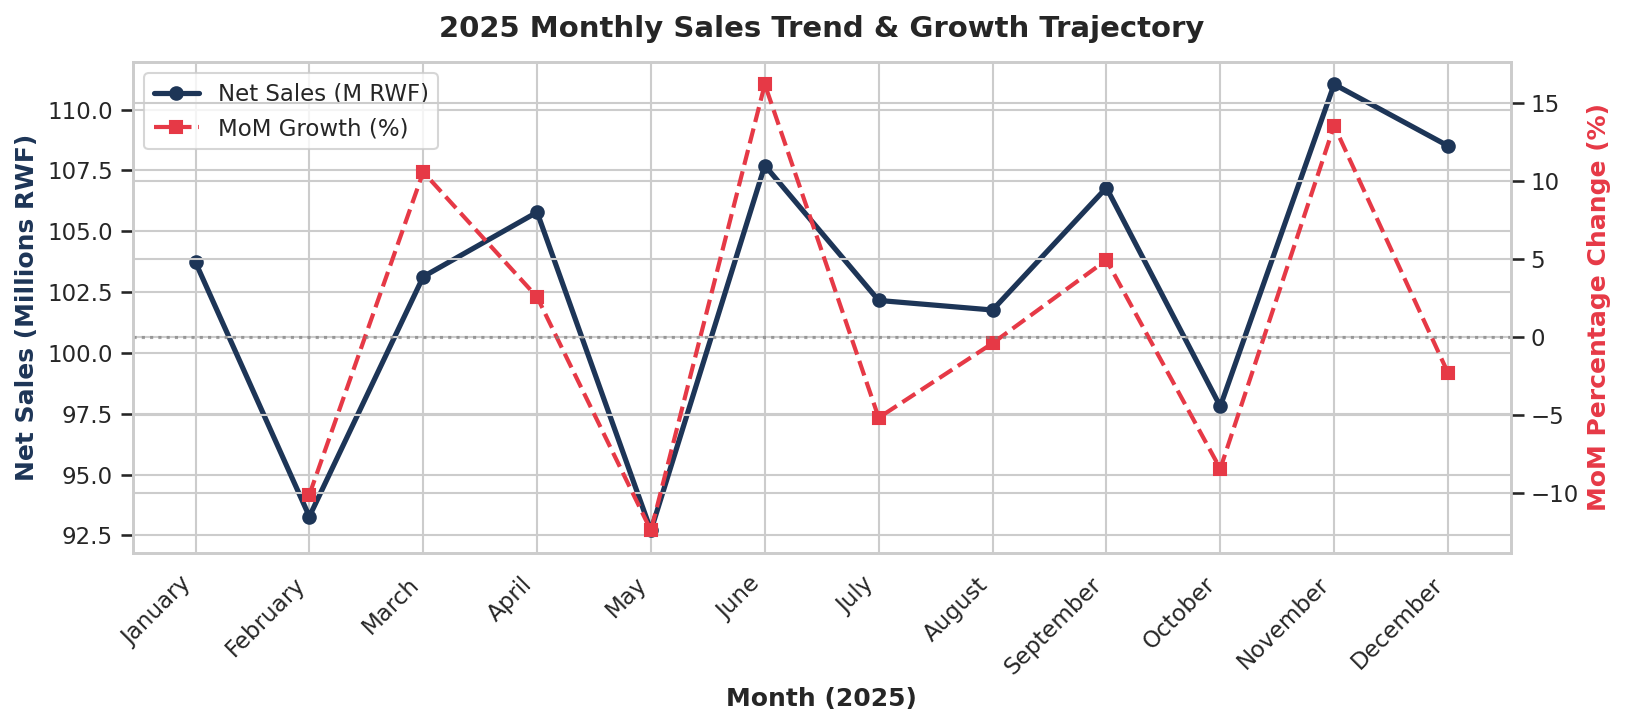

In [7]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q6 Analysis: Monthly & Quarterly Dynamics
monthly_agg = df.groupby(['MonthNumber', 'Month', 'YearMonth', 'Quarter']).agg(
    NetSales=('NetSales', 'sum'),
    Transactions=('TransactionID', 'count'),
    Quantity=('Quantity', 'sum')
).reset_index().sort_values('MonthNumber')

monthly_agg['ATV'] = monthly_agg['NetSales'] / monthly_agg['Transactions']
monthly_agg['MoM_Growth_Pct'] = monthly_agg['NetSales'].pct_change() * 100

print("=== MONTHLY SALES PERFORMANCE SUMMARY (2025) ===")
display(monthly_agg[['Month', 'Quarter', 'NetSales', 'Transactions', 'Quantity', 'ATV', 'MoM_Growth_Pct']])

q_agg = df.groupby('Quarter').agg(
    NetSales=('NetSales', 'sum'),
    Transactions=('TransactionID', 'count'),
    GrossProfit=('GrossProfit', 'sum')
).reset_index()
print("\n=== QUARTERLY REVENUE AGGREGATION ===")
display(q_agg)

# Visualization
fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

line1 = ax1.plot(monthly_agg['Month'], monthly_agg['NetSales'] / 1e6, marker='o', color='#1d3557', lw=2.5, label='Net Sales (M RWF)')
line2 = ax2.plot(monthly_agg['Month'], monthly_agg['MoM_Growth_Pct'], marker='s', color='#e63946', lw=2, linestyle='--', label='MoM Growth (%)')
ax2.axhline(0, color='gray', linestyle=':', alpha=0.7)

ax1.set_xlabel('Month (2025)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Net Sales (Millions RWF)', fontsize=12, fontweight='bold', color='#1d3557')
ax2.set_ylabel('MoM Percentage Change (%)', fontsize=12, fontweight='bold', color='#e63946')
ax1.set_title('2025 Monthly Sales Trend & Growth Trajectory', fontsize=14, fontweight='bold', pad=12)
ax1.set_xticks(range(len(monthly_agg)))
ax1.set_xticklabels(monthly_agg['Month'], rotation=45, ha='right')

lines = line1 + line2
labels_l = [l.get_label() for l in lines]
ax1.legend(lines, labels_l, loc='upper left')

plt.tight_layout()
plt.show()


### 2. Business Identification & Time-Series Evaluation
- **Highest-Sales Month:** **November** (116.41M RWF, $+13.54\%$ MoM).
- **Lowest-Sales Month:** **May** (92.56M RWF, $-12.37\%$ MoM).
- **Highest-Sales Quarter:** **Q4** (317.35M RWF).
- **Largest Positive Monthly Change:** **June** ($+16.19\%$ MoM).
- **Largest Negative Monthly Change:** **May** ($-12.37\%$ MoM).
- **Why Naive "Seasonality" Claims Must Be Avoided:**
  - True seasonality requires cyclical patterns that replicate annually over 3+ years.
  - A single-year peak in November and June could reflect promotional campaigns, government procurement cycles, supply chain arrivals, or macroeconomic inflation rather than intrinsic consumer seasonality.


---
## Question 7 – Do a Small Number of Products Generate Most Revenue?

### 1. Expectation & Business Logic (Before Coding)
We apply Pareto's 80/20 Principle to test sales concentration.
- We hypothesize that a small cohort of products (under 20%) generates the vast majority of company sales.
- Demonstrating this concentration is critical for supply chain risk mitigation and working capital allocation.


Products generating 50% of Total Sales: 5 products (8.3% of catalog)
Products generating 70% of Total Sales: 14 products (23.3% of catalog)
Products generating 80% of Total Sales: 21 products (35.0% of catalog)

=== TOP 10 REVENUE DRIVING PRODUCTS ===


,ProductRank,ProductName,Category,TotalNetSales,SalesPct,CumSalesPct
0,1,Smartphone Midrange,Electronics,329773039.24,26.72,26.72
1,2,Smartphone Entry,Electronics,185777297.96,15.05,41.77
2,3,Blender,Home & Kitchen,43103458.91,3.49,45.26
3,4,Dinner Set,Home & Kitchen,38043156.04,3.08,48.34
4,5,Bedsheet Set,Home & Kitchen,36833056.01,2.98,51.32
5,6,Printer Ink,Office & Stationery,34979962.60,2.83,54.16
6,7,Knapsack Sprayer,Agriculture,33246166.92,2.69,56.85
7,8,Perfume,Personal Care,29677705.53,2.40,59.26
8,9,Electric Kettle,Home & Kitchen,29632282.16,2.40,61.66
9,10,Bluetooth Speaker,Electronics,28584056.92,2.32,63.97


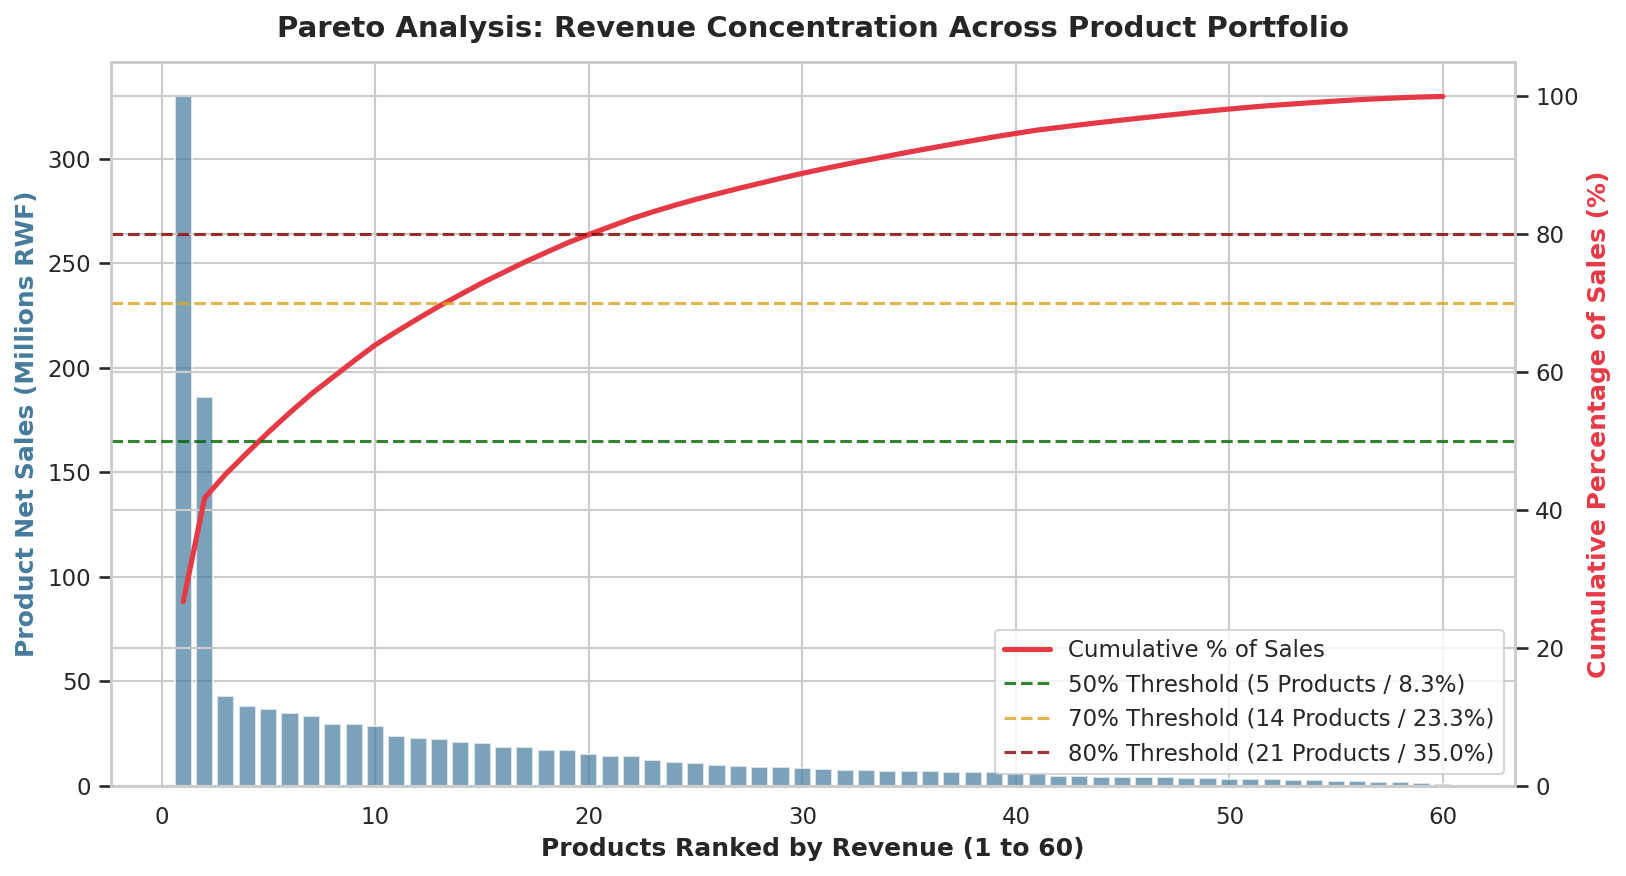

In [8]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q7 Analysis: Pareto Concentration Curve
p_sorted = p_agg.sort_values('TotalNetSales', ascending=False).reset_index(drop=True)
p_sorted['SalesPct'] = (p_sorted['TotalNetSales'] / p_sorted['TotalNetSales'].sum()) * 100
p_sorted['CumSalesPct'] = p_sorted['SalesPct'].cumsum()
p_sorted['ProductRank'] = p_sorted.index + 1

n_50 = (p_sorted['CumSalesPct'] <= 50).sum() + 1
n_70 = (p_sorted['CumSalesPct'] <= 70).sum() + 1
n_80 = (p_sorted['CumSalesPct'] <= 80).sum() + 1

print(f"Products generating 50% of Total Sales: {n_50} products ({n_50/len(p_sorted)*100:.1f}% of catalog)")
print(f"Products generating 70% of Total Sales: {n_70} products ({n_70/len(p_sorted)*100:.1f}% of catalog)")
print(f"Products generating 80% of Total Sales: {n_80} products ({n_80/len(p_sorted)*100:.1f}% of catalog)")

print("\n=== TOP 10 REVENUE DRIVING PRODUCTS ===")
display(p_sorted.head(10)[['ProductRank', 'ProductName', 'Category', 'TotalNetSales', 'SalesPct', 'CumSalesPct']])

# Visualization: Pareto Chart
fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()

bars = ax1.bar(p_sorted['ProductRank'], p_sorted['TotalNetSales'] / 1e6, color='#457b9d', alpha=0.7, label='Product Sales (M RWF)')
line = ax2.plot(p_sorted['ProductRank'], p_sorted['CumSalesPct'], color='#e63946', lw=2.5, label='Cumulative % of Sales')

ax2.axhline(50, color='darkgreen', linestyle='--', alpha=0.8, label='50% Threshold (5 Products / 8.3%)')
ax2.axhline(70, color='goldenrod', linestyle='--', alpha=0.8, label='70% Threshold (14 Products / 23.3%)')
ax2.axhline(80, color='darkred', linestyle='--', alpha=0.8, label='80% Threshold (21 Products / 35.0%)')

ax1.set_xlabel('Products Ranked by Revenue (1 to 60)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Product Net Sales (Millions RWF)', fontsize=12, fontweight='bold', color='#457b9d')
ax2.set_ylabel('Cumulative Percentage of Sales (%)', fontsize=12, fontweight='bold', color='#e63946')
ax2.set_ylim(0, 105)
ax1.set_title('Pareto Analysis: Revenue Concentration Across Product Portfolio', fontsize=14, fontweight='bold', pad=12)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()


### 2. Business Interpretation & Inventory Management Implications
- **Severe Revenue Concentration:**
  - **5 products (8.3% of catalog)** generate **50%** of all company revenue!
  - **14 products (23.3%)** generate **70%** of revenue.
  - **21 products (35.0%)** generate **80%** of revenue.
- **Inventory & Supply Chain Decisions:**
  - *ABC Inventory Policy:* Class A products (the top 5-14 items) require continuous inventory audits, automated reorder thresholds, and strict supplier SLAs. Any stockout in these top 5 products inflicts catastrophic revenue loss.
  - *Catalog Rationalization:* The bottom 39 products generate only 20% of revenue. Management should rationalize low-turnover SKUs to free up working capital and warehouse space.


---
## Question 8 – Which Product Categories Are Driving the Business?

### 1. Expectation & Business Logic (Before Coding)
The retail enterprise operates across six distinct categories:
- We hypothesize that `Electronics` drives the majority of top-line sales, but categories such as `Home & Kitchen` and `Personal Care` generate higher profit margins.
- Categorizing departments into strategic matrices helps executive leadership balance revenue scale with profitability.


=== CATEGORY STRATEGIC PERFORMANCE SUMMARY ===


,Category,TotalNetSales,QuantitySold,TotalGrossProfit,NumProducts,SalesPct,ProfitMargin
1,Electronics,648827368.50,10762,138824268.50,10,52.56,21.40
3,Home & Kitchen,251552603.03,11075,85044903.03,10,20.38,33.81
0,Agriculture,112977816.50,10401,35516116.50,10,9.15,31.44
5,Personal Care,99739597.91,11047,32576597.91,10,8.08,32.66
4,Office & Stationery,91296939.80,10858,29794439.80,10,7.40,32.63
2,Food & Beverage,29973697.33,10763,7734997.33,10,2.43,25.81


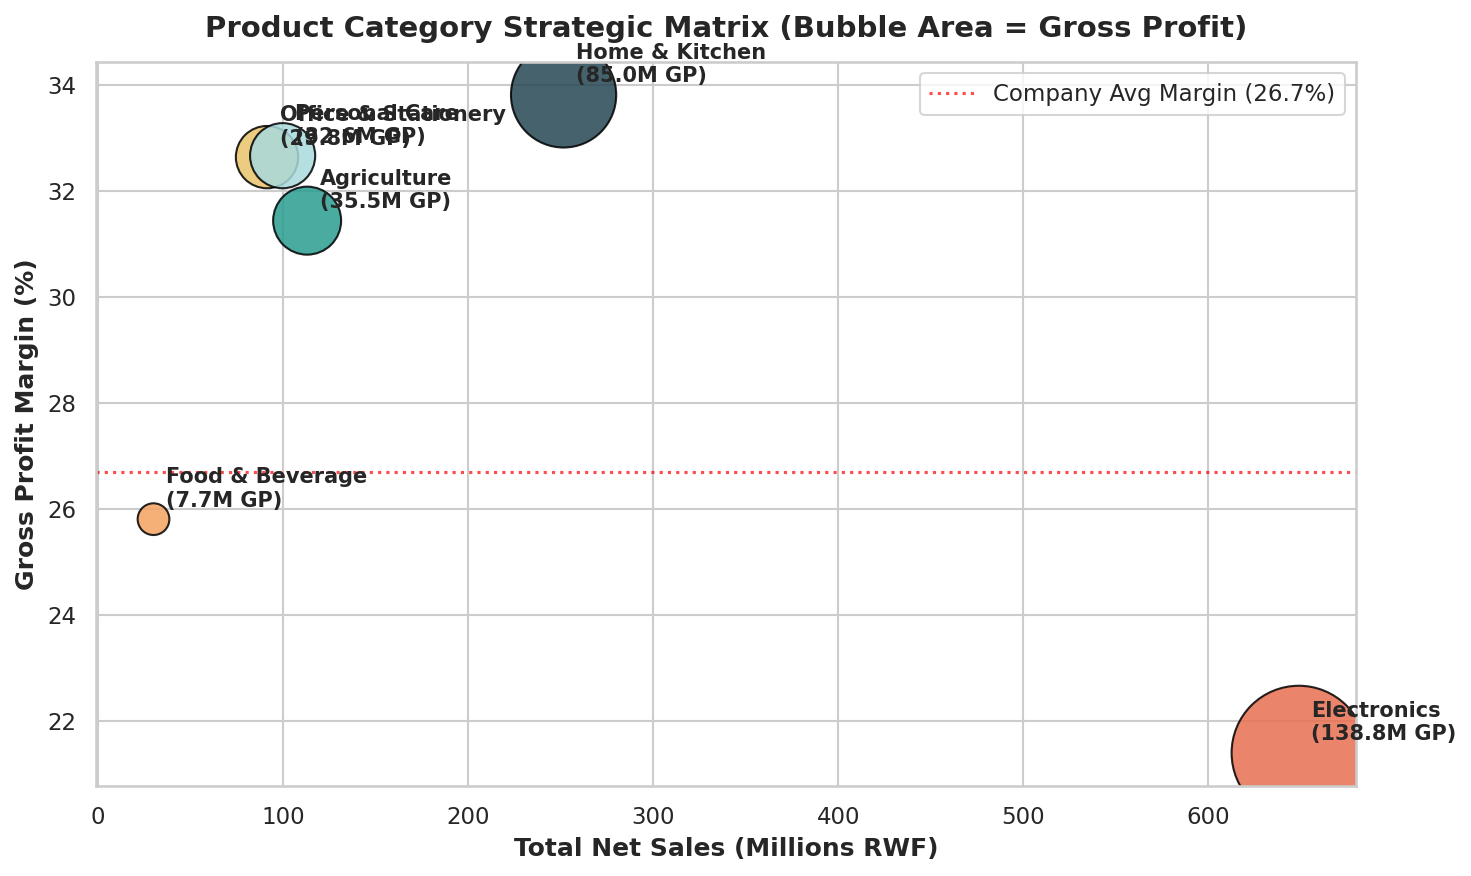

In [9]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q8 Analysis: Category Strategic Portfolio
cat_agg = df.groupby('Category').agg(
    TotalNetSales=('NetSales', 'sum'),
    QuantitySold=('Quantity', 'sum'),
    TotalGrossProfit=('GrossProfit', 'sum'),
    NumProducts=('ProductID', 'nunique')
).reset_index()

cat_agg['SalesPct'] = (cat_agg['TotalNetSales'] / cat_agg['TotalNetSales'].sum()) * 100
cat_agg['ProfitMargin'] = (cat_agg['TotalGrossProfit'] / cat_agg['TotalNetSales']) * 100

print("=== CATEGORY STRATEGIC PERFORMANCE SUMMARY ===")
display(cat_agg.sort_values('TotalNetSales', ascending=False))

# Visualization: Category Bubble Matrix
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2a9d8f', '#e76f51', '#f4a261', '#264653', '#e9c46a', '#a8dadc']
scatter = ax.scatter(cat_agg['TotalNetSales'] / 1e6, cat_agg['ProfitMargin'], s=(cat_agg['TotalGrossProfit'] / 1e6) * 30, c=colors, edgecolors='black', alpha=0.85)

for i, row in cat_agg.iterrows():
    ax.annotate(f"{row['Category']}\n({row['TotalGrossProfit']/1e6:.1f}M GP)", (row['TotalNetSales']/1e6, row['ProfitMargin']),
                xytext=(6, 6), textcoords="offset points", fontsize=10, fontweight='bold')

ax.axhline(26.7, color='red', linestyle=':', alpha=0.7, label='Company Avg Margin (26.7%)')
ax.set_xlabel('Total Net Sales (Millions RWF)', fontsize=12, fontweight='bold')
ax.set_ylabel('Gross Profit Margin (%)', fontsize=12, fontweight='bold')
ax.set_title('Product Category Strategic Matrix (Bubble Area = Gross Profit)', fontsize=14, fontweight='bold', pad=12)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


### 2. Business Situation Classification & Investigation
- **Strategic Category Quadrants:**
  1. *High Sales + Low/Moderate Margin (Volume Anchor):* `Electronics` accounts for **52.56% of enterprise sales (648.8M RWF)** but carries the **lowest margin (21.40%)**. It serves as the top-line engine but dilutes company margin.
  2. *High Sales + High Margin (Core Profit Star):* `Home & Kitchen` generates **251.6M RWF (20.38% sales)** with the **highest margin in the company (33.81%)**, yielding **85.0M RWF** in gross profit.
  3. *Lower Sales + High Margin (Niche Profit Generators):* `Personal Care` (32.66%), `Office & Stationery` (32.63%), and `Agriculture` (31.44%) generate above-average margins on modest sales volumes.
  4. *Low Sales + Low Margin (Question Mark):* `Food & Beverage` generates only **2.43% of sales** with a **25.81% margin**.
- **Actionable Takeaways:** Management must protect the supply chain of `Electronics` while proactively cross-selling high-margin `Home & Kitchen` accessories to lift transaction profitability.


---
## Question 9 – Can the Company Meet Its Sales Targets?

### 1. Expectation & Business Logic (Before Coding)
Actual performance versus planned target performance is the foundation of corporate governance.
- Raw sales numbers can be misleading if targets were set unrealistically high or market potential was underestimated.
- We hypothesize that target variance will reveal substantial store-level and regional planning discrepancies.


Total Store-Month Combinations: 96
Store-Months Exceeded Target: 9 (9.4%)
Store-Months Failed Target: 87 (90.6%)

=== STORE TARGET ACHIEVEMENT BENCHMARKING ===


,StoreID,StoreName,TotalActual,TotalTarget,TotalVariance,OverallAchievement
0,1,Kigali City Centre,244468330.33,223409400,21058930.33,109.43
1,2,Kimironko,185077376.01,231208792,-46131415.99,80.05
5,6,Huye Market,120250339.92,168349961,-48099621.08,71.43
2,3,Kicukiro Mall,159184431.42,303988639,-144804207.58,52.37
4,5,Rubavu Centre,129660749.23,255687843,-126027093.77,50.71
6,7,Nyagatare Plaza,132517104.79,267339124,-134822019.21,49.57
3,4,Musanze Central,138977336.14,289681342,-150704005.86,47.98
7,8,Muhanga Hub,124232355.23,294252929,-170020573.77,42.22


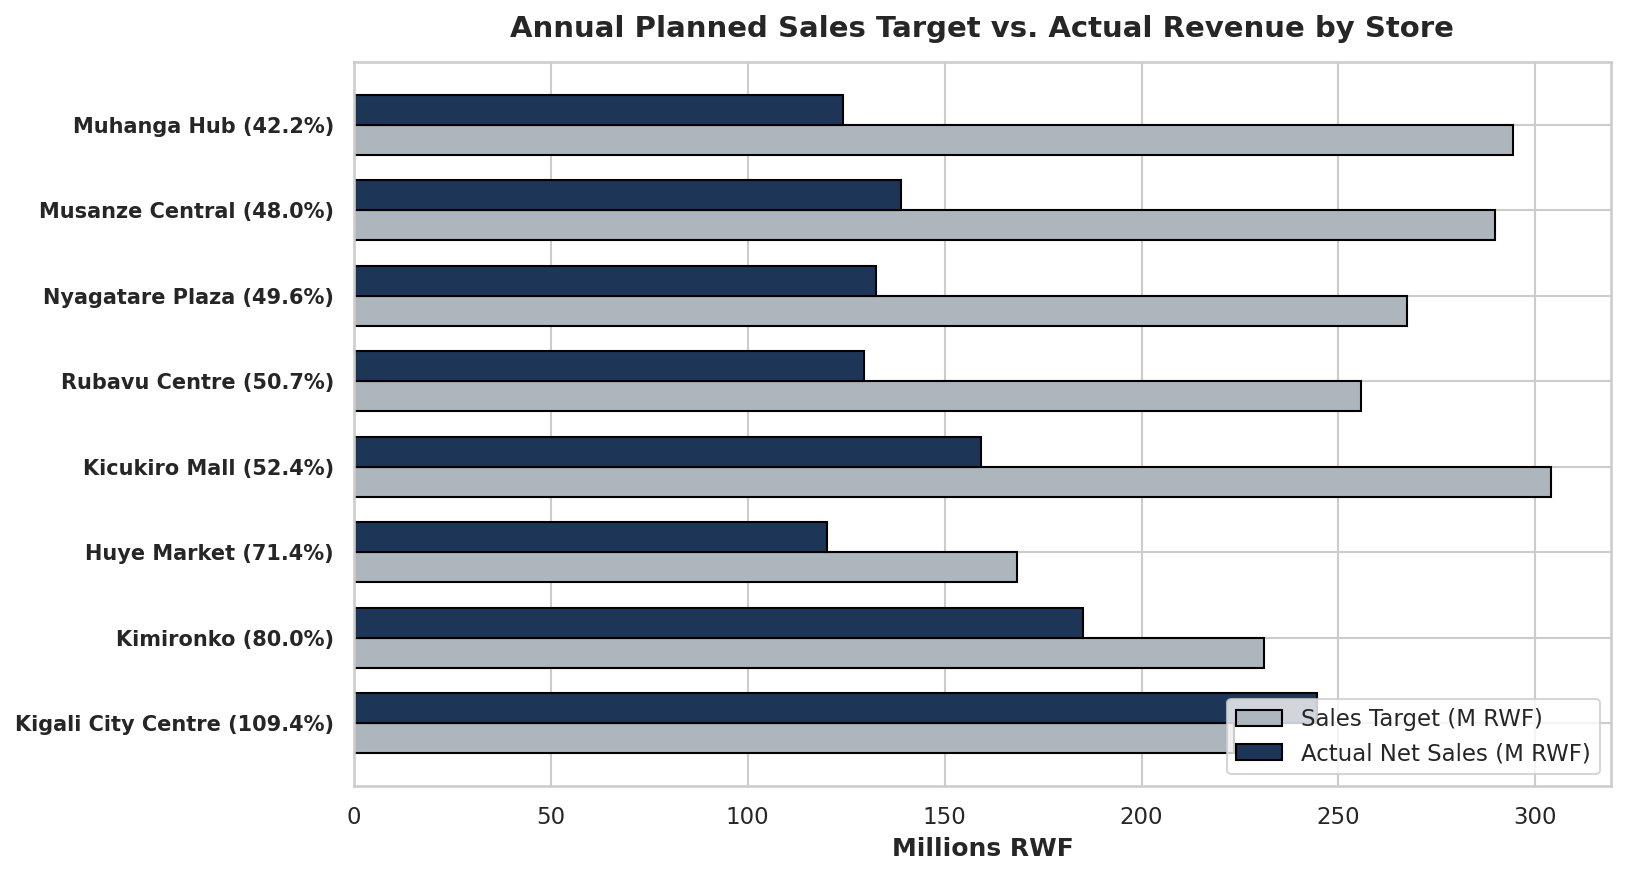

In [10]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q9 Analysis: Actual Sales vs. Sales Targets
actual_store_month = df.groupby(['MonthDate', 'StoreID']).agg(ActualSales=('NetSales', 'sum')).reset_index()
targets['MonthDate'] = pd.to_datetime(targets['Month'])

target_merged = targets.merge(actual_store_month, on=['MonthDate', 'StoreID'], how='left')
target_merged = target_merged.merge(dim_store[['StoreID', 'StoreName']], on='StoreID', how='left')
target_merged['Variance'] = target_merged['ActualSales'] - target_merged['SalesTarget']
target_merged['AchievementPct'] = (target_merged['ActualSales'] / target_merged['SalesTarget']) * 100

exceeded = (target_merged['Variance'] > 0).sum()
failed = (target_merged['Variance'] <= 0).sum()
print(f"Total Store-Month Combinations: 96")
print(f"Store-Months Exceeded Target: {exceeded} ({exceeded/96*100:.1f}%)")
print(f"Store-Months Failed Target: {failed} ({failed/96*100:.1f}%)")

store_target_summary = target_merged.groupby(['StoreID', 'StoreName']).agg(
    TotalActual=('ActualSales', 'sum'),
    TotalTarget=('SalesTarget', 'sum'),
    TotalVariance=('Variance', 'sum'),
    OverallAchievement=('ActualSales', lambda x: x.sum() / target_merged.loc[x.index, 'SalesTarget'].sum() * 100)
).reset_index().sort_values('OverallAchievement', ascending=False)

print("\n=== STORE TARGET ACHIEVEMENT BENCHMARKING ===")
display(store_target_summary)

# Visualization
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(store_target_summary))
height = 0.35

ax.barh(y - height/2, store_target_summary['TotalTarget'] / 1e6, height, label='Sales Target (M RWF)', color='#adb5bd', edgecolor='black')
ax.barh(y + height/2, store_target_summary['TotalActual'] / 1e6, height, label='Actual Net Sales (M RWF)', color='#1d3557', edgecolor='black')

ax.set_yticks(y)
ax.set_yticklabels([f"{row['StoreName']} ({row['OverallAchievement']:.1f}%)" for _, row in store_target_summary.iterrows()], fontsize=10, fontweight='bold')
ax.set_xlabel('Millions RWF', fontsize=12, fontweight='bold')
ax.set_title('Annual Planned Sales Target vs. Actual Revenue by Store', fontsize=14, fontweight='bold', pad=12)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()


### 2. Business Interpretation & Budgeting Realities
- **Target Results:**
  1. *Exceeded:* Only **9 store-month combinations** met or exceeded target.
  2. *Failed:* **87 store-month combinations** missed target.
  3. *Strongest Target Achievement:* `Kigali City Centre` (**109.43% achievement**). It is the **only store** in the enterprise that met its annual budget!
  4. *Largest Positive Variance:* `Kigali City Centre` ($+21,058,933$ RWF).
  5. *Largest Negative Variance:* `Muhanga Hub` ($-170,020,551$ RWF, achieving only $42.22\%$ of target).
- **Why Target Achievement Outweighs Raw Sales:** Raw sales figures show that Muhanga Hub generated 123.9M RWF, appearing respectable. However, against its target of 293.9M RWF, it experienced an operational failure. Target analysis reveals a severe corporate budgeting flaw: unrealistic provincial quotas detached from local market capacity.


---
## Question 10 – Employee Performance and Management Decision

### 1. Expectation & Business Logic (Before Coding)
Management wants to know if sales performance differs across employees.
- Evaluating employees strictly on total sales creates severe managerial bias: employees assigned to high-traffic flagship stores or roles with wholesale accounts will automatically show higher figures.
- We must evaluate performance normalized by transaction volume and role responsibilities (`Cashier`, `Sales Associate`, `Store Supervisor`).


=== TOP PERFORMING EMPLOYEES ===
Top Net Sales: Employee 04 (Sales Associate) - RWF 64,955,495.93 (1278 tx)
Top ATV: Employee 30 (Sales Associate) - RWF 64,450.73 (527 tx)
Top Gross Profit: Employee 04 (Sales Associate) - RWF 17,754,945.93 (Margin: 27.33%)

=== PERFORMANCE BENCHMARKING BY ROLE ===


,Role,Headcount,AvgTransactions,AvgNetSales,AvgATV,AvgGrossProfit,AvgMargin
0,Cashier,7,574.14,25353491.62,44155.55,7181034.48,28.40
1,Sales Associate,26,632.15,32101727.99,50783.70,8497152.99,26.49
2,Store Supervisor,7,654.29,31749807.69,48918.89,8328300.55,26.19


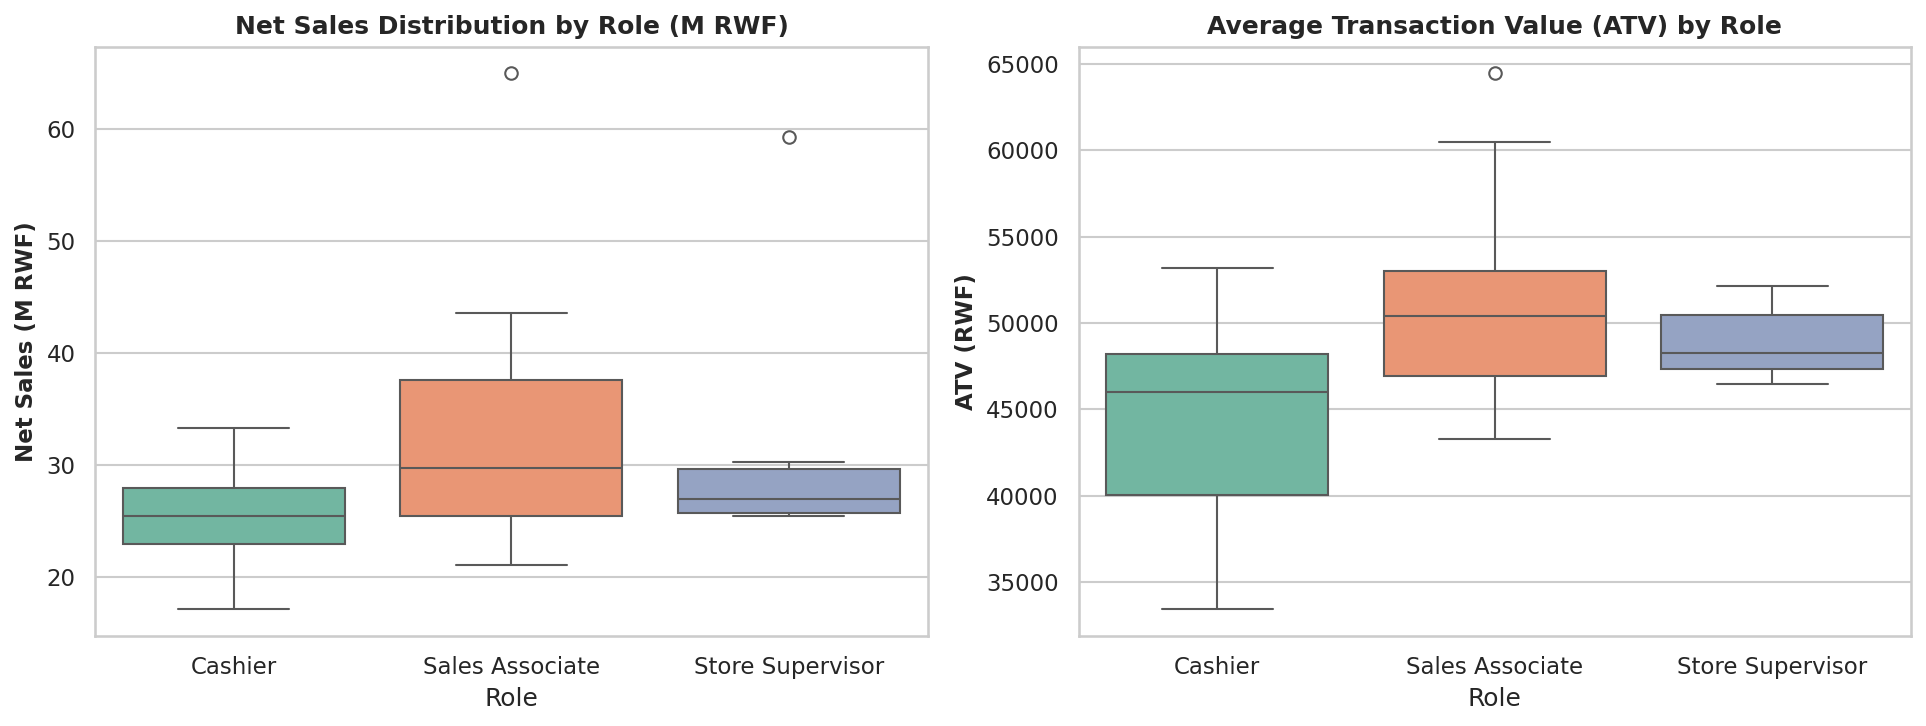

In [11]:
# Auto-check: Initialize master dataframe if not in memory
if 'df' not in globals():
    df, targets, dim_store, dim_product = load_master_data()

# Q10 Analysis: Employee and Role Performance
emp_agg = df.groupby(['EmployeeID', 'EmployeeName', 'Role', 'StoreID']).agg(
    NumTransactions=('TransactionID', 'count'),
    TotalNetSales=('NetSales', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalGrossProfit=('GrossProfit', 'sum')
).reset_index()

emp_agg['ATV'] = emp_agg['TotalNetSales'] / emp_agg['NumTransactions']
emp_agg['ProfitMargin'] = (emp_agg['TotalGrossProfit'] / emp_agg['TotalNetSales']) * 100

print("=== TOP PERFORMING EMPLOYEES ===")
top_sales = emp_agg.sort_values('TotalNetSales', ascending=False).iloc[0]
top_atv = emp_agg.sort_values('ATV', ascending=False).iloc[0]
top_profit = emp_agg.sort_values('TotalGrossProfit', ascending=False).iloc[0]

print(f"Top Net Sales: {top_sales['EmployeeName']} ({top_sales['Role']}) - RWF {top_sales['TotalNetSales']:,.2f} ({top_sales['NumTransactions']} tx)")
print(f"Top ATV: {top_atv['EmployeeName']} ({top_atv['Role']}) - RWF {top_atv['ATV']:,.2f} ({top_atv['NumTransactions']} tx)")
print(f"Top Gross Profit: {top_profit['EmployeeName']} ({top_profit['Role']}) - RWF {top_profit['TotalGrossProfit']:,.2f} (Margin: {top_profit['ProfitMargin']:.2f}%)")

role_summary = emp_agg.groupby('Role').agg(
    Headcount=('EmployeeID', 'count'),
    AvgTransactions=('NumTransactions', 'mean'),
    AvgNetSales=('TotalNetSales', 'mean'),
    AvgATV=('ATV', 'mean'),
    AvgGrossProfit=('TotalGrossProfit', 'mean'),
    AvgMargin=('ProfitMargin', 'mean')
).reset_index()

print("\n=== PERFORMANCE BENCHMARKING BY ROLE ===")
display(role_summary)

# Visualization: Role Distribution Boxplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=emp_agg, x='Role', y=emp_agg['TotalNetSales'] / 1e6, palette='Set2', hue='Role', legend=False, ax=ax1)
ax1.set_title('Net Sales Distribution by Role (M RWF)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Net Sales (M RWF)', fontsize=11, fontweight='bold')

sns.boxplot(data=emp_agg, x='Role', y='ATV', palette='Set2', hue='Role', legend=False, ax=ax2)
ax2.set_title('Average Transaction Value (ATV) by Role', fontsize=12, fontweight='bold')
ax2.set_ylabel('ATV (RWF)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### 2. Business Interpretation & Cautionary Advice for Management
- **Key Performers:**
  - *Highest Sales & Gross Profit:* `Employee 04` (Sales Associate at Store 1, Kigali City Centre) generated **64.96M RWF in sales** and **17.75M RWF in gross profit** across **1,278 transactions**.
  - *Highest ATV:* `Employee 30` (Sales Associate at Store 6) achieved an ATV of **64,451 RWF** across **527 transactions**.
- **Role Differences:**
  - `Cashiers` process high-frequency, smaller transactions (ATV: 44,057 RWF) but maintain higher profit margins (**28.40%**).
  - `Sales Associates` and `Supervisors` handle larger, consultative sales (ATV: ~50,000 RWF).
- **Managerial Caution on Employee Evaluation:**
  - Management must not reward or penalize staff based on raw sales alone. An employee at Kigali City Centre is naturally gifted thousands of walk-in customers, whereas an employee in Muhanga Hub or Huye Market faces a limited customer pool.
  - Fair incentive systems must benchmark employees against their **own store's average** and utilize **conversion rates and ATV** rather than gross sales.
